<a href="https://colab.research.google.com/github/ThePotatoSensei/Neuron-Simulation/blob/main/HodgkinHuxley.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [37]:

# Load packages for numeric computations (numpy) and plotting (matplotlib)

import numpy as np
import matplotlib.pyplot as plt

# The main functions for the Hodgkin-Huxley model are following this Github repository: https://github.com/swharden/pyHH

# The Hodgkin and Huxley model

In [38]:
# define the HH model

class HHModel:
    """The HHModel tracks conductances of 3 channels to calculate Vm"""

    # define the behavior of the gating variables behavior
    class Gate:
        """The Gate object manages a channel's kinetics and open state"""
        alpha, beta, state = 0, 0, 0

        def update(self, deltaTms):
            alphaState = self.alpha * (1-self.state)
            betaState = self.beta * self.state
            self.state += deltaTms * (alphaState - betaState)

        def setInfiniteState(self):
            self.state = self.alpha / (self.alpha + self.beta)

    # define default equilibrium potentials and conductances;
    # note that these values may be overwritten when running the program
    ENa, EK, EL = 50, -77, -54.4
    gNa, gK, gL = 120, 36, 0.3
    Cm = 1
    Vrest = -65  # the HH rate equations below are written relative to rest

    def __init__(self, startingVoltage=-65):
        self.m, self.n, self.h = self.Gate(), self.Gate(), self.Gate()
        self.Vm = startingVoltage
        self._UpdateGateTimeConstants(startingVoltage)
        self.m.setInfiniteState()
        self.n.setInfiniteState()
        self.h.setInfiniteState()

    @staticmethod
    def _vtrap(x, y):
        """x / (exp(x/y) - 1), using its limit y at x = 0 to avoid 0/0"""
        return y if abs(x) < 1e-6 else x / np.expm1(x / y)

    # update the voltage-dependent rate constants alpha and beta (1/ms) of each gate
    def _UpdateGateTimeConstants(self, Vm):
        """Update rate constants of all gates based on the given Vm"""
        V = Vm - self.Vrest
        self.n.alpha = .01 * self._vtrap(10-V, 10)
        self.n.beta = .125*np.exp(-V/80)
        self.m.alpha = .1 * self._vtrap(25-V, 10)
        self.m.beta = 4*np.exp(-V/18)
        self.h.alpha = .07*np.exp(-V/20)
        self.h.beta = 1/(np.exp((30-V)/10)+1)

    # update the membrane potential based on conductance-based and other currents
    def _UpdateCellVoltage(self, stimulusCurrent, deltaTms):
        """calculate channel currents using the latest gate time constants"""
        self.INa = np.power(self.m.state, 3) * self.gNa * \
            self.h.state*(self.Vm-self.ENa)
        self.IK = np.power(self.n.state, 4) * self.gK * (self.Vm-self.EK)
        self.IL = self.gL * (self.Vm-self.EL)
        Isum = stimulusCurrent - self.INa - self.IK - self.IL
        self.Vm += deltaTms * Isum / self.Cm

    def _UpdateGateStates(self, deltaTms):
        """calculate new channel open states using latest Vm"""
        self.n.update(deltaTms)
        self.m.update(deltaTms)
        self.h.update(deltaTms)

    def iterate(self, stimulusCurrent, deltaTms):
        self._UpdateGateTimeConstants(self.Vm)
        self._UpdateCellVoltage(stimulusCurrent, deltaTms)
        self._UpdateGateStates(deltaTms)

In [39]:
# define the simulation to be used

class Simulation:

    # initiate Hodgkin-Huxley model (defined above)
    def __init__(self, model):
        self.model = model
        self.CreateArrays(0, 0)
        pass

    # create arrays to contain variables and measurements
    def CreateArrays(self, pointCount, deltaTms):
        self.times = np.arange(pointCount) * deltaTms
        self.Vm = np.empty(pointCount)
        self.INa = np.empty(pointCount)
        self.IK = np.empty(pointCount)
        self.IL = np.empty(pointCount)
        self.StateN = np.empty(pointCount)
        self.StateM = np.empty(pointCount)
        self.StateH = np.empty(pointCount)

    # run the simulation based on the model,
    # using stimulus waveform and time step size as inputs
    def Run(self, stimulusWaveform, stepSizeMs):
        self.CreateArrays(len(stimulusWaveform), stepSizeMs)
        print(f"simulating {len(stimulusWaveform)} time points...")
        for i in range(len(stimulusWaveform)):
            self.model.iterate(stimulusWaveform[i], stepSizeMs)
            self.Vm[i] = self.model.Vm
            self.INa[i] = self.model.INa
            self.IK[i] = self.model.IK
            self.IL[i] = self.model.IL
            self.StateH[i] = self.model.h.state
            self.StateM[i] = self.model.m.state
            self.StateN[i] = self.model.n.state
        print("simulation complete")

In [57]:
# run the simulation

# customize a neuron model if desired
model = HHModel()
model.gNa = 120  # typically 120
model.gK = 36  # typically 36
model.EK = -77  # typically -77 mV
model.ENa = 50  # typically +50 mV

# time settings (ms)
dt = 0.01
t = np.arange(int(200 / dt)) * dt

# customize a stimulus waveform (µA/cm²), defined in ms so it works for any dt
stim = np.zeros(len(t))
ramp = (t >= 70) & (t < 180)
stim[ramp] = np.linspace(-20, 20, ramp.sum())
# let the model settle at its own resting potential before recording
for _ in range(int(50 / dt)):
    model.iterate(0, dt)

# simulate the model cell using the custom waveform
sim = Simulation(model)
sim.Run(stimulusWaveform=stim, stepSizeMs=dt)

simulating 20000 time points...
simulation complete


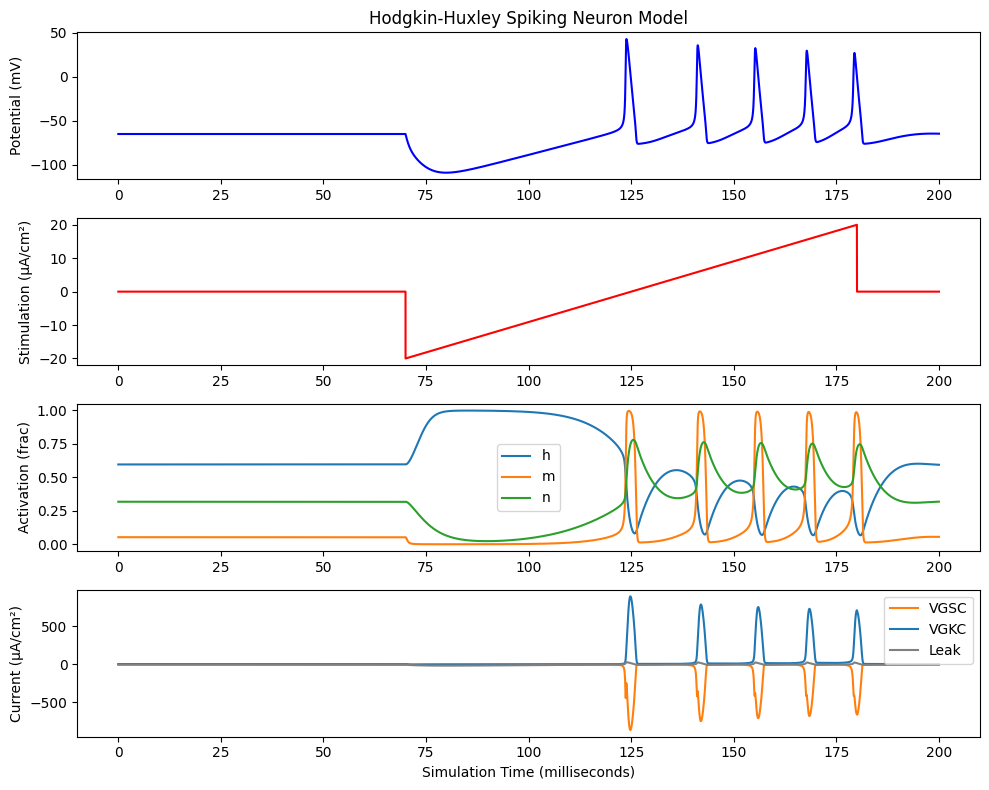

In [56]:
# plot the results with MatPlotLib
plt.figure(figsize=(10, 8))

ax1 = plt.subplot(411)
ax1.plot(sim.times, sim.Vm, color='b')
ax1.set_ylabel("Potential (mV)")
ax1.set_title("Hodgkin-Huxley Spiking Neuron Model")

ax2 = plt.subplot(412)
ax2.plot(sim.times, stim, color='r')
ax2.set_ylabel("Stimulation (µA/cm²)")

ax3 = plt.subplot(413, sharex=ax1)
ax3.plot(sim.times, sim.StateH, label='h')
ax3.plot(sim.times, sim.StateM, label='m')
ax3.plot(sim.times, sim.StateN, label='n')
ax3.set_ylabel("Activation (frac)")
ax3.legend()

ax4 = plt.subplot(414, sharex=ax1)
ax4.plot(sim.times, sim.INa, label='VGSC', color='tab:orange')
ax4.plot(sim.times, sim.IK, label='VGKC', color='tab:blue')
ax4.plot(sim.times, sim.IL, label='Leak', color='gray')
ax4.set_ylabel("Current (µA/cm²)")
ax4.set_xlabel("Simulation Time (milliseconds)")
ax4.legend()

plt.tight_layout()
plt.show()

# Network: a chain of neurons connected by synapses

**How to use it**
1. Run all the cells above once (they define `HHModel`).
2. Run the **network classes** cell below once.
3. Change only the **NETWORK SETTINGS** cell (number of neurons, synapse strength/type, stimulus), then run the settings, run and plot cells.

Neurons are connected in a chain: 1 → 2 → 3 → … Only neuron 1 receives the stimulus.
The overview plot shows all neurons together and a zoom with the delay from each neuron to the next; then every neuron gets its own copy of the usual 4-panel figure.

In [42]:
# define the network: a chain of HH neurons connected by synapses (1 -> 2 -> 3 -> ...)
# Run this cell once, after the HHModel cell. You do NOT need to edit it.

class Synapse:
    """Chemical synapse from one neuron to the next one in the chain
    (kinetic receptor model, Destexhe et al. 1994)"""

    # name: (reversal potential Esyn in mV, binding rate alpha in 1/(mM*ms), unbinding rate beta in 1/ms)
    TYPES = {
        "excitatory": (0.0, 1.1, 0.19),    # AMPA-like: pushes the next neuron towards firing
        "inhibitory": (-80.0, 5.0, 0.18),  # GABA_A-like: pushes the next neuron away from firing
    }

    def __init__(self, strength=0.5, kind="excitatory", delay_ms=0.0):
        self.gmax = strength          # maximum synaptic conductance (mS/cm²)
        self.kind = kind
        self.Esyn, self.alpha, self.beta = self.TYPES[kind]
        self.delay_ms = delay_ms      # extra axonal conduction delay (ms)
        self.s = 0.0                  # fraction of open receptors (0..1), works like a gate
        self.I = 0.0                  # synaptic current (µA/cm²), negative = flowing into the cell

    @staticmethod
    def transmitter(Vpre):
        """Transmitter in the cleft (mM): ~1 while the presynaptic neuron spikes, ~0 at rest"""
        return 1.0 / (1 + np.exp(-(Vpre - 2) / 5))

    def UpdateCurrent(self, Vpost):
        self.I = self.gmax * self.s * (Vpost - self.Esyn)
        return self.I

    def UpdateState(self, Vpre, deltaTms):
        T = self.transmitter(Vpre)
        self.s += deltaTms * (self.alpha * T * (1 - self.s) - self.beta * self.s)


class NeuronRecording:
    """Everything recorded from one neuron (same names as in the Simulation class)"""

    def __init__(self, pointCount, deltaTms):
        self.times = np.arange(pointCount) * deltaTms
        self.Vm = np.empty(pointCount)
        self.INa = np.empty(pointCount)
        self.IK = np.empty(pointCount)
        self.IL = np.empty(pointCount)
        self.StateN = np.empty(pointCount)
        self.StateM = np.empty(pointCount)
        self.StateH = np.empty(pointCount)
        self.Input = np.empty(pointCount)     # stimulus (neuron 1) or synaptic input (other neurons)
        self.SynapseS = np.zeros(pointCount)  # open fraction of the synapse arriving at this neuron
        self.spikeTimes = np.array([])


class Network:
    """A chain of HH neurons: neuron 1 -> synapse -> neuron 2 -> synapse -> neuron 3 ...
    Only neuron 1 receives the stimulus."""

    def __init__(self, nNeurons=2, synapseStrength=0.5, synapseType="excitatory",
                 synapseDelayMs=0.0, neuronChanges=None):
        # ---- check the settings and give clear error messages ----
        if not isinstance(nNeurons, int) or nNeurons < 1:
            raise ValueError(f"N_NEURONS must be a whole number of at least 1 (you wrote {nNeurons!r})")
        if synapseType not in Synapse.TYPES:
            raise ValueError(f"SYNAPSE_TYPE must be one of {list(Synapse.TYPES)} (you wrote {synapseType!r})")
        if np.isscalar(synapseStrength):
            strengths = [synapseStrength] * (nNeurons - 1)
        else:
            strengths = list(synapseStrength)
            if len(strengths) != nNeurons - 1:
                raise ValueError(f"SYNAPSE_STRENGTH is a list, so it needs one value per synapse: "
                                 f"{nNeurons - 1} values for {nNeurons} neurons (you gave {len(strengths)})")
        if any(g < 0 for g in strengths):
            raise ValueError("SYNAPSE_STRENGTH cannot be negative (use SYNAPSE_TYPE = 'inhibitory' instead)")
        if synapseDelayMs < 0:
            raise ValueError("SYNAPSE_DELAY_MS cannot be negative")

        # ---- build the neurons ----
        self.neurons = [HHModel() for _ in range(nNeurons)]
        for number, changes in (neuronChanges or {}).items():
            if number not in range(1, nNeurons + 1):
                raise ValueError(f"NEURON_CHANGES mentions neuron {number}, but neurons are numbered 1 to {nNeurons}")
            for name, value in changes.items():
                if not hasattr(self.neurons[number - 1], name):
                    raise ValueError(f"NEURON_CHANGES: neurons have no parameter called {name!r} "
                                     f"(options: gNa, gK, gL, ENa, EK, EL, Cm)")
                setattr(self.neurons[number - 1], name, value)

        # ---- build the synapses: synapse k connects neuron k to neuron k+1 ----
        self.synapses = [Synapse(g, synapseType, synapseDelayMs) for g in strengths]

    def Run(self, stimulusWaveform, stepSizeMs, settleMs=50):
        nPoints = len(stimulusWaveform)
        nNeurons = len(self.neurons)
        dt = stepSizeMs

        # let all neurons settle at rest before recording
        for _ in range(int(settleMs / dt)):
            for neuron in self.neurons:
                neuron.iterate(0, dt)
        restV = [neuron.Vm for neuron in self.neurons]

        self.recordings = [NeuronRecording(nPoints, dt) for _ in range(nNeurons)]
        self.stimulus = np.asarray(stimulusWaveform, dtype=float)
        delaySteps = [int(round(syn.delay_ms / dt)) for syn in self.synapses]

        print(f"simulating {nNeurons} neuron(s) x {nPoints} time points...")
        for i in range(nPoints):
            # 1) input current of each neuron: stimulus for neuron 1, synapse for the others
            inputs = [self.stimulus[i]]
            for k, syn in enumerate(self.synapses):
                inputs.append(-syn.UpdateCurrent(self.neurons[k + 1].Vm))

            # 2) voltage seen by each synapse = presynaptic voltage, 'delay' ms ago
            Vpre = []
            for k in range(len(self.synapses)):
                j = i - 1 - delaySteps[k]
                Vpre.append(self.recordings[k].Vm[j] if j >= 0 else restV[k])

            # 3) advance neurons and synapses by one time step
            for neuron, I in zip(self.neurons, inputs):
                neuron.iterate(I, dt)
            for k, syn in enumerate(self.synapses):
                syn.UpdateState(Vpre[k], dt)

            # 4) record
            for k, (neuron, rec) in enumerate(zip(self.neurons, self.recordings)):
                rec.Vm[i] = neuron.Vm
                rec.INa[i] = neuron.INa
                rec.IK[i] = neuron.IK
                rec.IL[i] = neuron.IL
                rec.StateN[i] = neuron.n.state
                rec.StateM[i] = neuron.m.state
                rec.StateH[i] = neuron.h.state
                rec.Input[i] = inputs[k]
                if k > 0:
                    rec.SynapseS[i] = self.synapses[k - 1].s

        # spike times = moments when Vm crosses 0 mV going up
        for rec in self.recordings:
            up = (rec.Vm[1:] > 0) & (rec.Vm[:-1] <= 0)
            rec.spikeTimes = rec.times[1:][up]
        print("simulation complete\n")
        self.PrintSummary()

    def Delays(self, k):
        """Delay (ms) of each spike of neuron k+1 after the last spike of neuron k (0-based k)"""
        pre = self.recordings[k].spikeTimes
        post = self.recordings[k + 1].spikeTimes
        delays = []
        for tp in post:
            earlier = pre[pre < tp]
            if len(earlier):
                delays.append(tp - earlier[-1])
        return np.array(delays)

    def PrintSummary(self):
        first = self.recordings[0].spikeTimes
        for k, rec in enumerate(self.recordings):
            n = len(rec.spikeTimes)
            line = f"Neuron {k + 1}: "
            if n == 0:
                line += "did not fire"
                if k == 0:
                    line += "  (stimulus too weak?)"
                elif self.synapses[k - 1].kind == "inhibitory":
                    line += "  (normal for an inhibitory synapse: look for the dip (IPSP) in its plot)"
                elif len(self.recordings[k - 1].spikeTimes) == 0:
                    line += f"  (neuron {k} did not fire, so nothing reached it)"
                else:
                    line += "  (synapse too weak: try a larger SYNAPSE_STRENGTH)"
            else:
                line += f"{n} spike(s), first at {rec.spikeTimes[0]:.2f} ms"
                if k > 0:
                    d = self.Delays(k - 1)
                    if len(d):
                        line += f"  | delay from neuron {k}: {d[0]:.2f} ms"
                        if len(d) > 1:
                            line += f" (mean over {len(d)} spikes: {d.mean():.2f} ms)"
                    if len(first):
                        line += f"  | total from neuron 1: {rec.spikeTimes[0] - first[0]:.2f} ms"
            print(line)


def PlotNeuron(net, k):
    """Same 4 panels as the single-neuron plot, for neuron k+1 of the network"""
    rec = net.recordings[k]
    plt.figure(figsize=(10, 8))

    ax1 = plt.subplot(411)
    ax1.plot(rec.times, rec.Vm, color='b')
    ax1.set_ylabel("Potential (mV)")
    title = f"Neuron {k + 1}"
    title += " (receives the stimulus)" if k == 0 else f" (receives a synapse from neuron {k})"
    ax1.set_title(title)

    ax2 = plt.subplot(412, sharex=ax1)
    if k == 0:
        ax2.plot(rec.times, rec.Input, color='r')
        ax2.set_ylabel("Stimulation (µA/cm²)")
    else:
        ax2.plot(rec.times, rec.Input, color='purple')
        ax2.set_ylabel("Synaptic input\n(µA/cm², + = depolarizing)")

    ax3 = plt.subplot(413, sharex=ax1)
    ax3.plot(rec.times, rec.StateH, label='h')
    ax3.plot(rec.times, rec.StateM, label='m')
    ax3.plot(rec.times, rec.StateN, label='n')
    ax3.set_ylabel("Activation (frac)")
    ax3.legend(loc="upper right")

    ax4 = plt.subplot(414, sharex=ax1)
    ax4.plot(rec.times, rec.INa, label='VGSC', color='tab:orange')
    ax4.plot(rec.times, rec.IK, label='VGKC', color='tab:blue')
    ax4.plot(rec.times, rec.IL, label='Leak', color='gray')
    ax4.set_ylabel("Current (µA/cm²)")
    ax4.set_xlabel("Simulation Time (milliseconds)")
    ax4.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


def PlotOverview(net):
    """All neurons together, plus a zoom on the first spikes showing the delays"""
    recs = net.recordings
    t = recs[0].times
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(recs)))
    fired = [rec.spikeTimes[0] for rec in recs if len(rec.spikeTimes)]

    fig, axs = plt.subplots(3, 1, figsize=(10, 9), gridspec_kw={'height_ratios': [2, 2, 1]})

    # full time course
    for k, rec in enumerate(recs):
        axs[0].plot(t, rec.Vm, color=colors[k], label=f"Neuron {k + 1}")
    axs[0].set_ylabel("Potential (mV)")
    axs[0].set_title(f"Network overview: {len(recs)} neuron(s) in a chain, "
                     f"{net.synapses[0].kind if net.synapses else 'no'} synapses")
    axs[0].legend(loc="upper right")

    # zoom on the first spike of each neuron, with the delays
    if fired and len(recs) > 1:
        t0, t1 = fired[0] - 3, max(fired) + 12
        for k, rec in enumerate(recs):
            axs[1].plot(t, rec.Vm, color=colors[k], label=f"Neuron {k + 1}")
            if len(rec.spikeTimes):
                axs[1].axvline(rec.spikeTimes[0], color=colors[k], ls='--', lw=0.8)
        for k in range(len(recs) - 1):
            d = net.Delays(k)
            if len(d):
                tpost = recs[k + 1].spikeTimes[0]
                tpre = tpost - d[0]
                y = 55 + 12 * (k % 3)
                axs[1].annotate("", xy=(tpost, y), xytext=(tpre, y),
                                arrowprops=dict(arrowstyle="<->", color='k', lw=1))
                axs[1].text((tpre + tpost) / 2, y + 2, f"{k + 1}→{k + 2}: {d[0]:.2f} ms",
                            ha='center', va='bottom', fontsize=9)
        axs[1].set_xlim(t0, t1)
        axs[1].set_ylim(-90, 95)
        axs[1].set_title("Zoom on the first spikes (dashed lines = spike times at 0 mV)")
    else:
        axs[1].text(0.5, 0.5, "No delays to show: neuron 1 did not fire, or there is only one neuron",
                    ha='center', va='center', transform=axs[1].transAxes)
        axs[1].set_xticks([]); axs[1].set_yticks([])
    axs[1].set_ylabel("Potential (mV)")

    # stimulus to neuron 1
    axs[2].plot(t, net.stimulus, color='r')
    axs[2].set_ylabel("Stimulation\nneuron 1 (µA/cm²)")
    axs[2].set_xlabel("Simulation Time (milliseconds)")
    axs[2].sharex(axs[0])

    plt.tight_layout()
    plt.show()

In [43]:
# ======================= NETWORK SETTINGS: edit only this cell =======================

N_NEURONS = 2                 # how many neurons in the chain: 1, 2, 3, ... (1 -> 2 -> 3 ...)

SYNAPSE_TYPE = "inhibitory"   # "excitatory" or "inhibitory"
SYNAPSE_STRENGTH = 0.5        # mS/cm². Below ~0.1 the next neuron does not fire.
                              # One number = same for all synapses, or a list with one value
                              # per synapse, e.g. [0.5, 0.2] for 3 neurons
SYNAPSE_DELAY_MS = 0.0        # extra axonal conduction delay (ms); 0 = no extra delay

NEURON_CHANGES = {}           # optional, change single neurons, e.g.
                              # {2: {"gNa": 60}}  -> neuron 2 has half the Na channels
                              # {3: {"gK": 30, "EK": -70}}

# time settings (ms)
dt = 0.01
DURATION_MS = 200

# stimulus: ONLY neuron 1 receives it
STIM_START_MS = 50
STIM_DURATION_MS = 1
STIM_AMPLITUDE = 20           # µA/cm²

# ====================================================================================

t = np.arange(int(DURATION_MS / dt)) * dt
stim = np.zeros(len(t))
stim[(t >= STIM_START_MS) & (t < STIM_START_MS + STIM_DURATION_MS)] = STIM_AMPLITUDE
# any other waveform works too (noise, pulse train...), as long as stim has len(t) values

In [44]:
# build and run the network (no need to edit)

net = Network(nNeurons=N_NEURONS,
              synapseStrength=SYNAPSE_STRENGTH,
              synapseType=SYNAPSE_TYPE,
              synapseDelayMs=SYNAPSE_DELAY_MS,
              neuronChanges=NEURON_CHANGES)
net.Run(stimulusWaveform=stim, stepSizeMs=dt)

simulating 2 neuron(s) x 20000 time points...
simulation complete

Neuron 1: 1 spike(s), first at 51.31 ms
Neuron 2: did not fire  (normal for an inhibitory synapse: look for the dip (IPSP) in its plot)


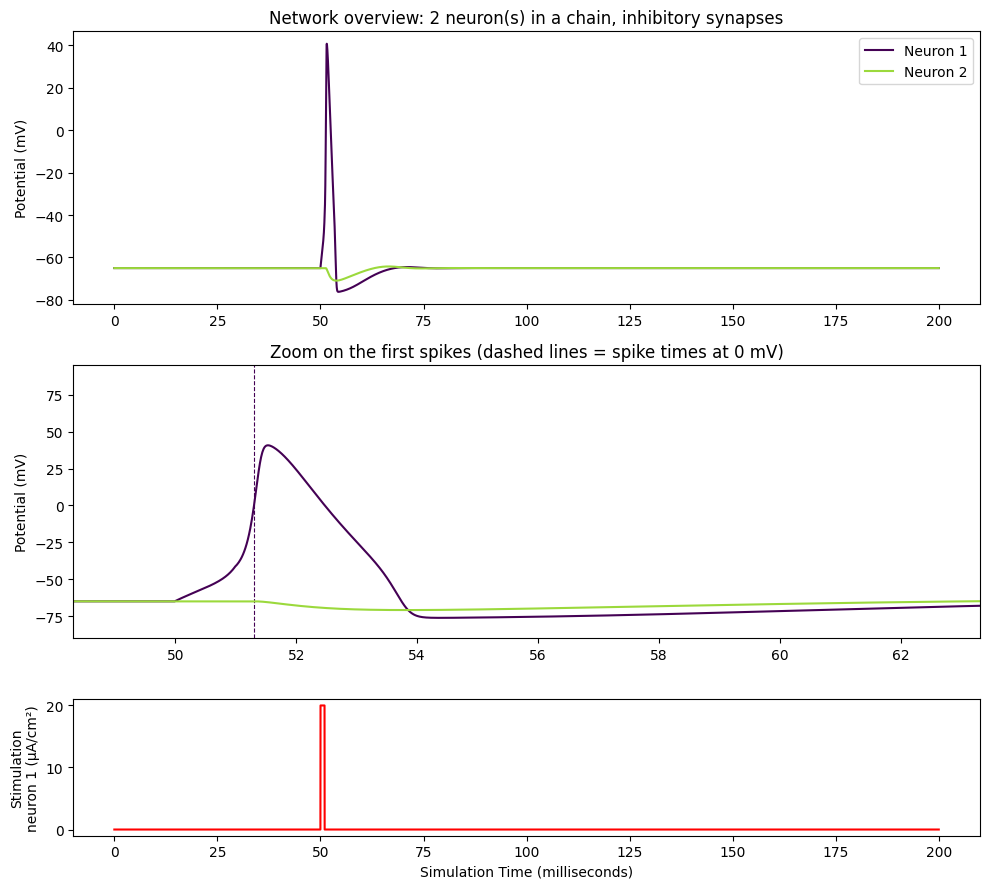

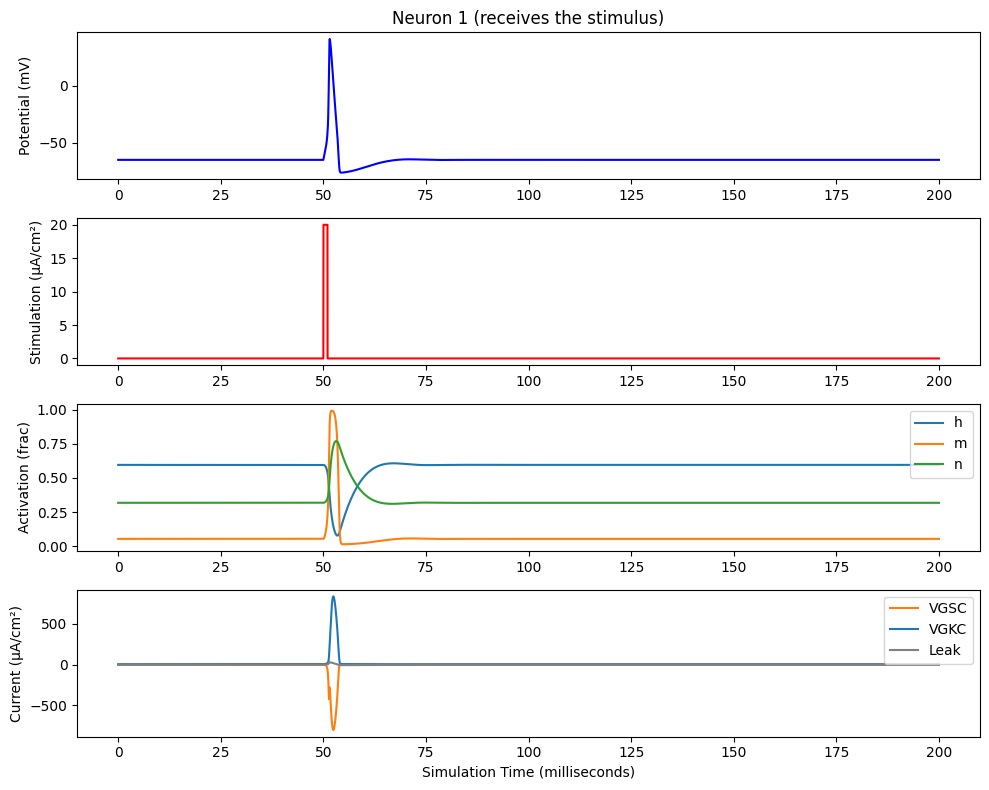

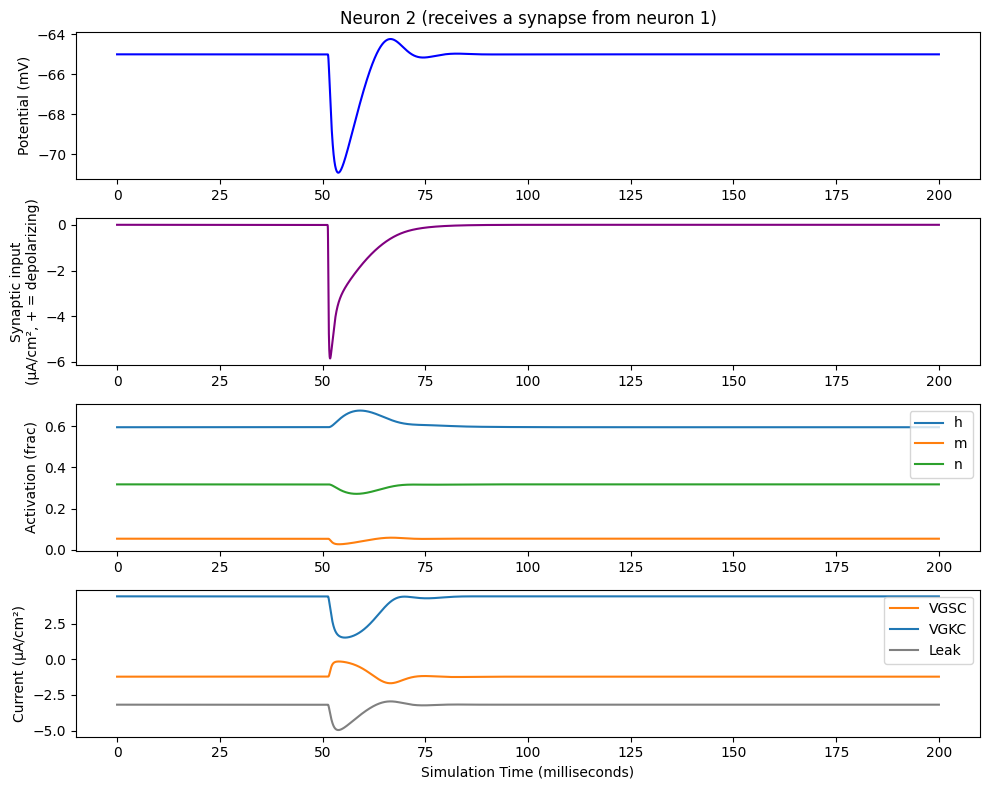

In [45]:
# plot the network results (no need to edit)

# 1) overview: all neurons together + zoom with the delay from one neuron to the next
PlotOverview(net)

# 2) one copy of the usual 4-panel figure for every neuron
for k in range(len(net.neurons)):
    PlotNeuron(net, k)